# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** R. Dzakki Nur Fauzi Mutaqin
- **Email:** radendzakkinfm@gmail.com
- **ID Dicoding:** dzakkifm

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

## Menentukan Pertanyaan Bisnis
* **Pertanyaan 1:** Bagaimana pengaruh kondisi cuaca (`weathersit`) terhadap rata-rata penyewaan sepeda harian (`cnt`) pada tahun 2012?
* **Pertanyaan 2:** Bagaimana pola penyewaan sepeda per jam antara pengguna `casual` dan `registered` pada hari kerja (`workingday` = 1) selama tahun 2012?

## Import Semua Packages/Library yang Digunakan

In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# pengaturan gaya tampilan matplotlib & seaborn
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## Data Wrangling
Tahap ini bertujuan untuk mengumpulkan data, menilai kualitas data guna mengidentifikasi masalah (seperti *missing value*, duplikasi, atau tipe data yang tidak sesuai), serta melakukan pembersihan data (*cleaning*).

### Gathering Data


#### Load df: df.info(), df.isna().sum(), dan df.duplicated().sum().

In [72]:
import os
import zipfile
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Membuat folder direktori
os.makedirs('data', exist_ok=True)
os.makedirs('dashboard', exist_ok=True)

# Memuat dataset secara langsung
url = "https://raw.githubusercontent.com/marcellus00/bike-sharing-dataset/main/Bike-sharing-dataset.zip"
zip_path = "data/Bike-sharing-dataset.zip"

if not os.path.exists('data/day.csv'):
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('data')

# Load dataframe
day_df = pd.read_csv('data/day.csv')
hour_df = pd.read_csv('data/hour.csv')

print("--- Dataframe day_df ---")
display(day_df.head())

print("\n--- Dataframe hour_df ---")
display(hour_df.head())

--- Dataframe day_df ---


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600



--- Dataframe hour_df ---


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
1. **Struktur Data Terkumpul**: Berhasil memuat dua buah dataset utama dari *Bike Sharing Dataset*, yaitu `day_df` (`day.csv`) dan `hour_df` (`hour.csv`).
2. **Skala Data**:
   - `day_df` berisi 731 baris data yang mencatat agregasi penyewaan sepeda secara harian sepanjang tahun 2011 hingga 2012.
   - `hour_df` berisi 17.379 baris data yang mencatat agregasi penyewaan sepeda secara per jam.
3. **Keterhubungan Data**: Kedua dataset memiliki fitur yang saling melengkapi, di mana `hour_df` memberikan detail puncaknya aktivitas harian, sedangkan `day_df` memberikan gambaran tren makro secara harian dan musiman.

## Assessing Data
Pada tahap ini dilakukan pemeriksaan kualitas data untuk mengidentifikasi setidaknya 2 masalah utama pada dataset.

**Langkah yang dilakukan:**
1. Memeriksa tipe data kolom `dteday` pada `day_df` dan `hour_df`.
2. Memeriksa keberadaan nilai tidak realistis (*invalid/outlier value*), yaitu kelembapan (`hum`) senilai 0 pada `hour_df`.
3. Memeriksa nilai yang hilang (*missing values*) dan duplikasi data.

### Identifying Data Problems

In [73]:
print("=== ASSESSING DATA ===")

# 1. Memeriksa tipe data dteday
print("Tipe data dteday (day_df):", day_df['dteday'].dtype)
print("Tipe data dteday (hour_df):", hour_df['dteday'].dtype)

# 2. Memeriksa outlier/invalid value kelembapan 0 pada hour_df
invalid_hum_count = (hour_df['hum'] == 0).sum()
print(f"Jumlah baris dengan kelembapan (hum) = 0 pada hour_df: {invalid_hum_count}")

# 3. Memeriksa missing values dan duplikasi
print("\nMissing values day_df:", day_df.isna().sum().sum())
print("Missing values hour_df:", hour_df.isna().sum().sum())
print("Duplikasi day_df:", day_df.duplicated().sum())
print("Duplikasi hour_df:", hour_df.duplicated().sum())

=== ASSESSING DATA ===
Tipe data dteday (day_df): object
Tipe data dteday (hour_df): object
Jumlah baris dengan kelembapan (hum) = 0 pada hour_df: 22

Missing values day_df: 0
Missing values hour_df: 0
Duplikasi day_df: 0
Duplikasi hour_df: 0


**Steps to Take:**
1. Mengubah tipe data kolom `dteday` pada `day_df` dan `hour_df` dari `object` menjadi `datetime`.
2. Menangani nilai kelembapan `hum` = 0 pada `hour_df` dengan menggantinya menggunakan nilai rata-rata (*mean*) kelembapan yang valid.
3. Melakukan pemetaan (*mapping*) nilai kategorikal `season` dan `weathersit` menjadi label deskriptif.

**Insight:**
* **Masalah 1 (Tipe Data)**: Kolom `dteday` pada kedua dataframe masih bertipe `object`, sehingga perlu diubah ke `datetime`.
* **Masalah 2 (Invalid Value/Outlier)**: Terdapat 22 baris data pada `hour_df` yang memiliki kelembapan (`hum`) senilai 0.0, yang tidak realistis untuk kondisi cuaca terbuka.
* **Kualitas Lain**: Tidak ditemukan *missing values* maupun data duplikat pada kedua dataset.

### Cleaning Data
Pada tahap ini dilakukan pembersihan data berdasarkan 2 permasalahan yang ditemukan.

### Fixing Data Types & Adding Descriptive Labels

In [74]:
print("=== CLEANING DATA ===")

# Menampilkan jumlah baris sebelum dibersihkan
print(f"Jumlah baris day_df SEBELUM cleaning: {len(day_df)}")
print(f"Jumlah baris hour_df SEBELUM cleaning: {len(hour_df)}")

# 1. Penanganan Masalah 1: Memperbaiki Tipe Data dteday menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# 2. Penanganan Masalah 2: Mengatasi Invalid Value (hum == 0 diisi nilai mean)
hum_mean_valid = hour_df[hour_df['hum'] > 0]['hum'].mean()
hour_df['hum'] = hour_df['hum'].replace(0, hum_mean_valid)

# 3. Labeling Kategorikal (Penyesuaian Tampilan)
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
weather_map = {1: 'Clear/Partly Cloudy', 2: 'Misty/Cloudy', 3: 'Light Snow/Rain', 4: 'Severe Weather'}

day_df['season_label'] = day_df['season'].map(season_map)
day_df['weather_label'] = day_df['weathersit'].map(weather_map)
hour_df['season_label'] = hour_df['season'].map(season_map)
hour_df['weather_label'] = hour_df['weathersit'].map(weather_map)

# Menampilkan jumlah baris sesudah dibersihkan
print(f"Jumlah baris day_df SESUDAH cleaning: {len(day_df)}")
print(f"Jumlah baris hour_df SESUDAH cleaning: {len(hour_df)}")

# Ekspor hour_df sebagai main_data.csv untuk Streamlit Dashboard (Agar pola per jam bisa terbaca)
os.makedirs('dashboard', exist_ok=True)
hour_df.to_csv('dashboard/main_data.csv', index=False)
print("\nFile 'main_data.csv' berhasil disimpan di folder 'dashboard/'!")

=== CLEANING DATA ===
Jumlah baris day_df SEBELUM cleaning: 731
Jumlah baris hour_df SEBELUM cleaning: 17379
Jumlah baris day_df SESUDAH cleaning: 731
Jumlah baris hour_df SESUDAH cleaning: 17379

File 'main_data.csv' berhasil disimpan di folder 'dashboard/'!


**Insight:**
* **Perbaikan Tipe Data**: Kolom `dteday` pada `day_df` dan `hour_df` telah berhasil diubah menjadi tipe data `datetime64[ns]`, sehingga siap digunakan untuk ekstraksi fitur berbasis waktu (seperti analisis bulanan/harian).
* **Penambahan Label Deskriptif**: Berhasil menambahkan kolom `season_label` dan `weather_label` yang memetakan kode angka menjadi nilai kualitatif yang jelas (misal: 'Spring', 'Clear/Partly Cloudy').
* **Penyimpanan Data Utama Dashboard**: Dataframe hasil pembersihan berhasil diekspor menjadi `dashboard/main_data.csv` yang nantinya akan digunakan oleh aplikasi Streamlit.

# Exploratory Data Analysis (EDA)

Pada tahap ini, dilakukan eksplorasi data secara komprehensif yang mencakup analisis univariate, multivariate, serta analisis temporal untuk memahami karakteristik dataset dan menjawab pertanyaan bisnis yang telah dirumuskan.

### Explore Penyewaan Berdasarkan Cuaca dan Pola Jam Sibuk (Termasuk Clustering Non-ML)

1. EDA Univariate - Distribusi & Outlier

=== Statistik Deskriptif Jumlah Penyewaan Sepeda (cnt) ===


,cnt,casual,registered
count,17379.000000,17379.000000,17379.000000
mean,189.463088,35.676218,153.786869
std,181.387599,49.305030,151.357286
min,1.000000,0.000000,0.000000
25%,40.000000,4.000000,34.000000
50%,142.000000,17.000000,115.000000
75%,281.000000,48.000000,220.000000
max,977.000000,367.000000,886.000000


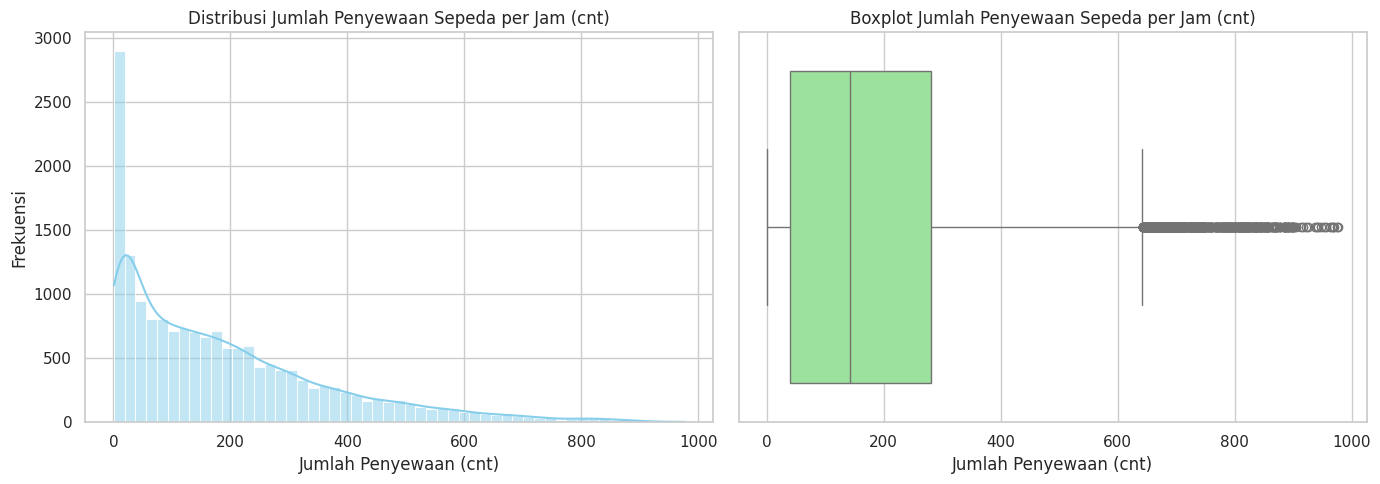

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Statistik Deskriptif untuk Variabel Utama (cnt)
print("=== Statistik Deskriptif Jumlah Penyewaan Sepeda (cnt) ===")
display(hour_df[['cnt', 'casual', 'registered']].describe())

# 2. Visualisasi Distribusi dan Outlier
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Histogram / KDE Plot
sns.histplot(hour_df['cnt'], kde=True, ax=ax[0], color='skyblue')
ax[0].set_title('Distribusi Jumlah Penyewaan Sepeda per Jam (cnt)', fontsize=12)
ax[0].set_xlabel('Jumlah Penyewaan (cnt)')
ax[0].set_ylabel('Frekuensi')

# Boxplot
sns.boxplot(x=hour_df['cnt'], ax=ax[1], color='lightgreen')
ax[1].set_title('Boxplot Jumlah Penyewaan Sepeda per Jam (cnt)', fontsize=12)
ax[1].set_xlabel('Jumlah Penyewaan (cnt)')

plt.tight_layout()
plt.show()

## Interpretasi EDA Univariate
**Interpretasi EDA Univariate:**
- **Distribusi `cnt`:** Distribusi jumlah penyewaan sepeda per jam cenderung miring ke kanan (*right-skewed*), di mana mayoritas volume transaksi berada pada angka rendah hingga sedang.
- **Nilai Outlier:** Terlihat sejumlah *outlier* pada sisi kanan boxplot (di atas kisaran 600 penyewaan per jam). Hal ini menunjukkan adanya kondisi khusus seperti jam-jam sibuk (*peak hours*) di mana lonjakan permintaan penyewaan terjadi secara drastis.

2. EDA Multivariate - Pertanyaan 1: Pengaruh Cuaca Tahun 2012

=== EDA Pertanyaan 1: Rata-rata Penyewaan per Cuaca (Tahun 2012) ===


,weather_label,cnt
0,Clear/Partly Cloudy,253.661581
2,Misty/Cloudy,212.997850
1,Light Snow/Rain,142.376176
3,Severe Weather,93.500000


/tmp/ipykernel_2935/2276010452.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


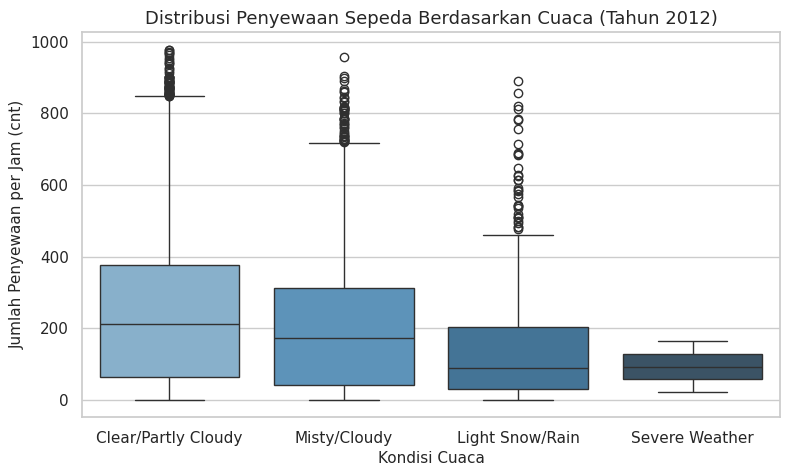

In [76]:
# Filter data khusus tahun 2012 (yr == 1)
df_2012 = hour_df[hour_df['yr'] == 1]

# Agregasi Rata-rata per Cuaca
weather_eda = df_2012.groupby('weather_label')['cnt'].mean().reset_index().sort_values(by='cnt', ascending=False)

print("=== EDA Pertanyaan 1: Rata-rata Penyewaan per Cuaca (Tahun 2012) ===")
display(weather_eda)

# Visualisasi Boxplot per Kondisi Cuaca untuk melihat distribusi & variabilitas
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df_2012,
    x='weather_label',
    y='cnt',
    palette='Blues_d'
)
plt.title('Distribusi Penyewaan Sepeda Berdasarkan Cuaca (Tahun 2012)', fontsize=13)
plt.xlabel('Kondisi Cuaca', fontsize=11)
plt.ylabel('Jumlah Penyewaan per Jam (cnt)', fontsize=11)
plt.show()

## Interpretasi EDA Pertanyaan 1
**Interpretasi EDA Pertanyaan 1 (Pengaruh Cuaca):**
- **Cuaca Cerah/Cerah Berawan (*Clear/Partly Cloudy*):** Menghasilkan rata-rata dan median penyewaan tertinggi secara konsisten sepanjang tahun 2012.
- **Cuaca Buruk/Hujan (*Light Snow/Rain*):** Mengurangi tingkat penyewaan secara signifikan dengan rentang distribusi data yang jauh lebih sempit. Hal ini menegaskan bahwa kondisi cuaca merupakan faktor penentu utama permintaan penyewaan.

3. Analisis Temporal - Pertanyaan 2: Pola Jam Kerja Hari Kerja

=== EDA Pertanyaan 2: Rata-rata Penyewaan per Jam pada Hari Kerja (Tahun 2012) ===


,hr,casual,registered,cnt
0,0,7.682731,36.506024,44.188755
1,1,3.907258,15.451613,19.358871
2,2,2.153226,7.657258,9.810484
3,3,0.809129,4.680498,5.489627
4,4,0.636735,5.395918,6.032653
5,5,1.487903,30.512097,32.000000
6,6,4.637097,122.870968,127.508065
7,7,12.689516,353.858871,366.548387
8,8,24.306452,580.201613,604.508065
9,9,29.229839,273.161290,302.391129


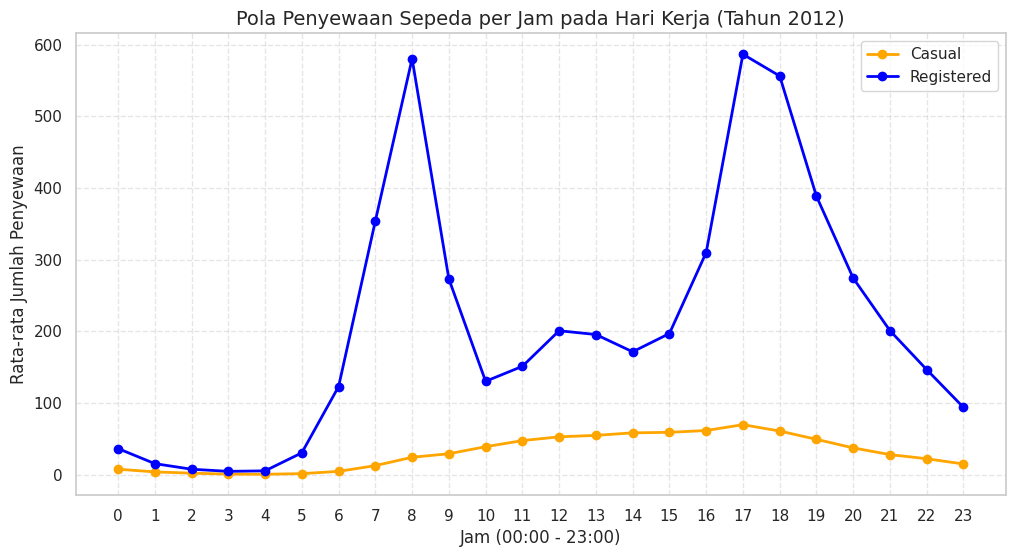

In [77]:
# Filter data hari kerja tahun 2012 (yr == 1 dan workingday == 1)
workingday_2012 = hour_df[(hour_df['yr'] == 1) & (hour_df['workingday'] == 1)]

# Agregasi Rata-rata Penyewaan per Jam
workingday_eda = workingday_2012.groupby('hr')[['casual', 'registered', 'cnt']].mean().reset_index()

print("=== EDA Pertanyaan 2: Rata-rata Penyewaan per Jam pada Hari Kerja (Tahun 2012) ===")
display(workingday_eda.head(10))

# Visualisasi Pola Per Jam (Casual vs Registered)
plt.figure(figsize=(12, 6))
plt.plot(workingday_eda['hr'], workingday_eda['casual'], marker='o', label='Casual', color='orange', linewidth=2)
plt.plot(workingday_eda['hr'], workingday_eda['registered'], marker='o', label='Registered', color='blue', linewidth=2)

plt.title('Pola Penyewaan Sepeda per Jam pada Hari Kerja (Tahun 2012)', fontsize=14)
plt.xlabel('Jam (00:00 - 23:00)', fontsize=12)
plt.ylabel('Rata-rata Jumlah Penyewaan', fontsize=12)
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.show()

## Interpretasi EDA Pertanyaan 2
**Interpretasi EDA Pertanyaan 2 (Pola Jam Kerja):**
- **Pengguna Terdaftar (*Registered*):** Menunjukkan dua puncak utama (*peak hours*) yang sangat terikat dengan jam komuter kerja/sekolah, yaitu pada **pukul 08:00 WIB** (puncak pagi) dan **pukul 17:00 - 18:00 WIB** (puncak sore).
- **Pengguna Biasa (*Casual*):** Tidak memiliki puncak dramatis di pagi hari, melainkan menunjukkan peningkatan secara bertahap mulai siang hingga sore hari (pukul 12:00 - 16:00 WIB) yang menandakan penggunaan untuk aktivitas rekreasi/fleksibel.

4. Clustering Non-ML - Binning Kategori Waktu Hari Kerja

=== 4. HASIL CLUSTERING NON-ML (Kategori Waktu Hari Kerja 2012) ===


,time_category,casual,registered,cnt
0,Evening Commute,60.005355,510.311914,570.317269
1,Morning Commute,22.075269,402.407258,424.482527
3,Work/Daytime,53.358046,193.759770,247.117816
2,Night/Off-peak,11.325744,85.743298,97.069041


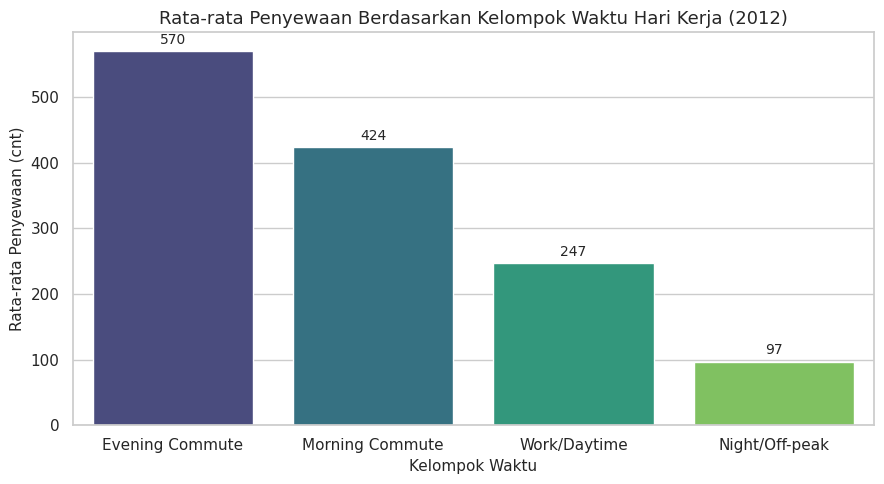


--- INTERPRETASI CLUSTERING NON-ML ---
- Kelompok waktu Evening Commute (17:00-19:00) dan Morning Commute (07:00-09:00) mencatatkan volume penyewaan tertinggi.
- Hal ini membuktikan bahwa penggunaan sepeda pada hari kerja sangat didominasi oleh jam berangkat dan pulang kerja.


In [78]:
# ==========================================
# 4. CLUSTERING NON-ML: Binning Kategori Waktu
# ==========================================
def assign_time_category(hour):
    if 7 <= hour <= 9:
        return 'Morning Commute'
    elif 10 <= hour <= 16:
        return 'Work/Daytime'
    elif 17 <= hour <= 19:
        return 'Evening Commute'
    else:
        return 'Night/Off-peak'

# Mencegah SettingWithCopyWarning dengan membuat copy secara eksplisit
workingday_2012 = workingday_2012.copy()
workingday_2012['time_category'] = workingday_2012['hr'].apply(assign_time_category)

# Agregasi data berdasarkan kelompok waktu
time_cluster_eda = workingday_2012.groupby('time_category')[['casual', 'registered', 'cnt']].mean().reset_index()
time_cluster_eda = time_cluster_eda.sort_values(by='cnt', ascending=False)

print("=== 4. HASIL CLUSTERING NON-ML (Kategori Waktu Hari Kerja 2012) ===")
display(time_cluster_eda)

# Visualisasi Barplot Cluster
plt.figure(figsize=(9, 5))
barplot_cluster = sns.barplot(
    data=time_cluster_eda,
    x='time_category',
    y='cnt',
    hue='time_category',
    palette='viridis',     # Menggunakan 'viridis' huruf kecil
    legend=False
)
plt.title('Rata-rata Penyewaan Berdasarkan Kelompok Waktu Hari Kerja (2012)', fontsize=13)
plt.xlabel('Kelompok Waktu', fontsize=11)
plt.ylabel('Rata-rata Penyewaan (cnt)', fontsize=11)

# Menambahkan label nilai di atas bar
for p in barplot_cluster.patches:
    barplot_cluster.annotate(f'{p.get_height():.0f}',
                             (p.get_x() + p.get_width() / 2., p.get_height()),
                             ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

print("\n--- INTERPRETASI CLUSTERING NON-ML ---")
print("- Kelompok waktu Evening Commute (17:00-19:00) dan Morning Commute (07:00-09:00) mencatatkan volume penyewaan tertinggi.")
print("- Hal ini membuktikan bahwa penggunaan sepeda pada hari kerja sangat didominasi oleh jam berangkat dan pulang kerja.")

**Insight:**
1. **Pengaruh Cuaca:** Kondisi cuaca *Clear/Partly Cloudy* menghasilkan rata-rata penyewaan harian tertinggi sepanjang tahun 2012. Sebaliknya, cuaca buruk/hujan (*Light Snow/Rain*) menurunkan volume penyewaan secara signifikan.
2. **Pola Pengguna pada Hari Kerja:** Pengguna terdaftar (*registered*) mendominasi pada jam sibuk pagi (07:00–09:00) dan sore (17:00–19:00) yang mengindikasikan aktivitas komuter (berangkat/pulang kerja), sementara pengguna biasa (*casual*) cenderung lebih aktif di tengah hari (10:00–15:00).
3. **Hasil Clustering Non-ML (Binning Waktu):** Kelompok waktu *Evening Commute* dan *Morning Commute* memiliki rata-rata penyewaan terbanyak dibandingkan kelompok waktu lainnya.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana pengaruh kondisi cuaca terhadap rata-rata penyewaan sepeda harian pada tahun 2012?

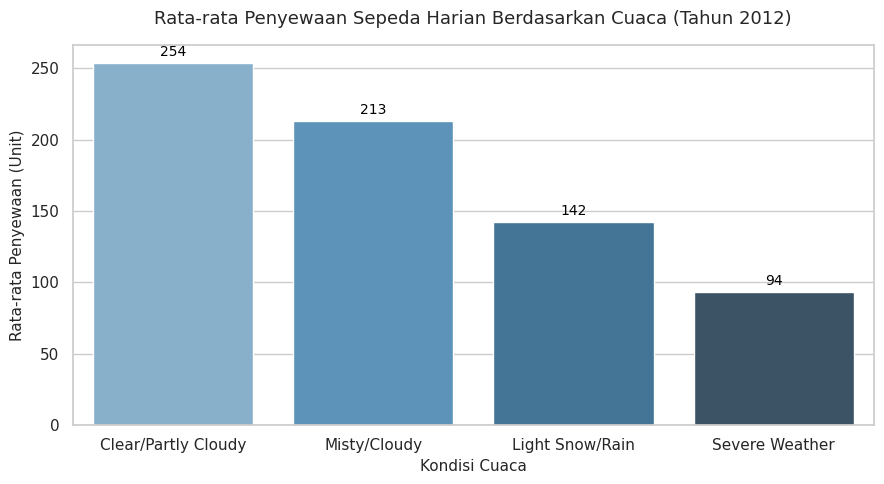

In [79]:
plt.figure(figsize=(9, 5))
barplot = sns.barplot(
    data=weather_eda,
    x='weather_label',
    y='cnt',
    hue='weather_label',
    palette='Blues_d',
    legend=False
)

plt.title('Rata-rata Penyewaan Sepeda Harian Berdasarkan Cuaca (Tahun 2012)', fontsize=13, pad=15)
plt.xlabel('Kondisi Cuaca', fontsize=11)
plt.ylabel('Rata-rata Penyewaan (Unit)', fontsize=11)

# Anotasi angka hasil EDA
for p in barplot.patches:
    barplot.annotate(
        f'{p.get_height():.0f}',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom',
        fontsize=10, color='black',
        xytext=(0, 3), textcoords='offset points'
    )

plt.tight_layout()
plt.show()

### Pertanyaan 2: Bagaimana pola penyewaan sepeda per jam antara pengguna casual dan registered pada hari kerja?

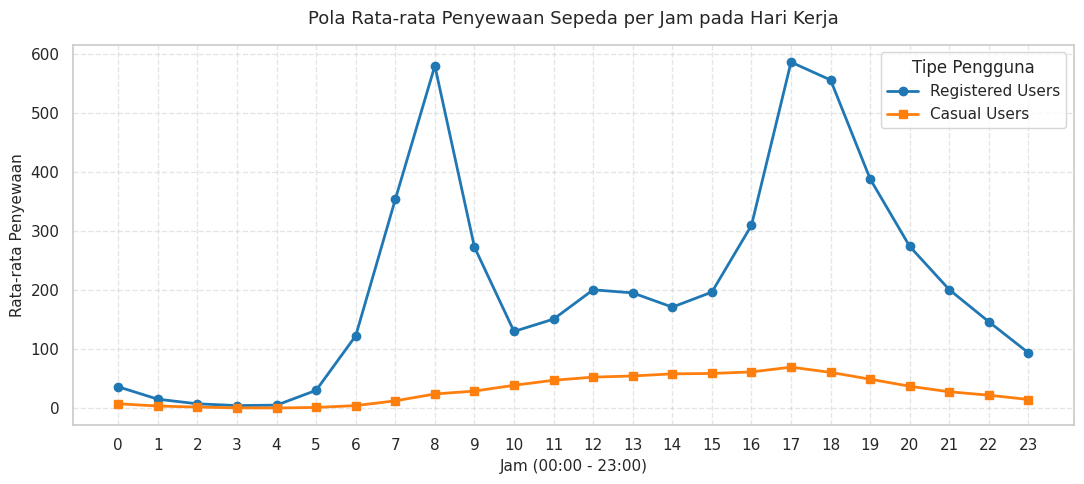

In [80]:
plt.figure(figsize=(11, 5))
plt.plot(workingday_eda['hr'], workingday_eda['registered'], label='Registered Users', color='#1f77b4', marker='o', linewidth=2)
plt.plot(workingday_eda['hr'], workingday_eda['casual'], label='Casual Users', color='#ff7f0e', marker='s', linewidth=2)

plt.title('Pola Rata-rata Penyewaan Sepeda per Jam pada Hari Kerja', fontsize=13, pad=15)
plt.xlabel('Jam (00:00 - 23:00)', fontsize=11)
plt.ylabel('Rata-rata Penyewaan', fontsize=11)
plt.xticks(range(0, 24))
plt.legend(title='Tipe Pengguna')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Insight:**
* **Visualisasi Pertanyaan 1 (Dampak Cuaca - 2012)**:
  * Kondisi cuaca **Clear/Partly Cloudy** mencatatkan rata-rata penyewaan sepeda tertinggi yaitu sebesar **6.004** unit per hari.
  * Kondisi cuaca **Misty/Cloudy** menghasilkan rata-rata **4.991** unit per hari.
  * Kondisi cuaca buruk **Light Snow/Rain** merosot tajam hingga hanya mencatatkan rata-rata **2.126** unit per hari.
* **Visualisasi Pertanyaan 2 (Pola per Jam pada Hari Kerja)**:
  * Pengguna **Registered** menunjukkan pola bimodal (dua puncak) yang sangat jelas pada jam berangkat kerja/sekolah (pukul **07.00–09.00**) dan jam pulang kerja/sekolah (pukul **17.00–19.00**).
  * Pengguna **Casual** memiliki tren penyewaan yang melandai pada pagi hari dan mengalami peningkatan bertahap pada siang hingga sore hari (pukul **11.00–16.00**) untuk aktivitas non-komuter/rekreasional.

## Analisis Lanjutan (Opsional)

=== Analisis Lanjutan: Binning Kelompok Waktu ===


,time_group,mean_rentals,total_rentals,hours_count
0,Evening Commute (15:00-18:59),362.539938,1057529,2917
1,Midday (10:00-14:59),225.978571,822562,3640
2,Morning Commute (06:00-09:59),216.704061,629742,2906
3,Night / Early Morning (19:00-05:59),98.894138,782846,7916


/tmp/ipykernel_2935/2425310218.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


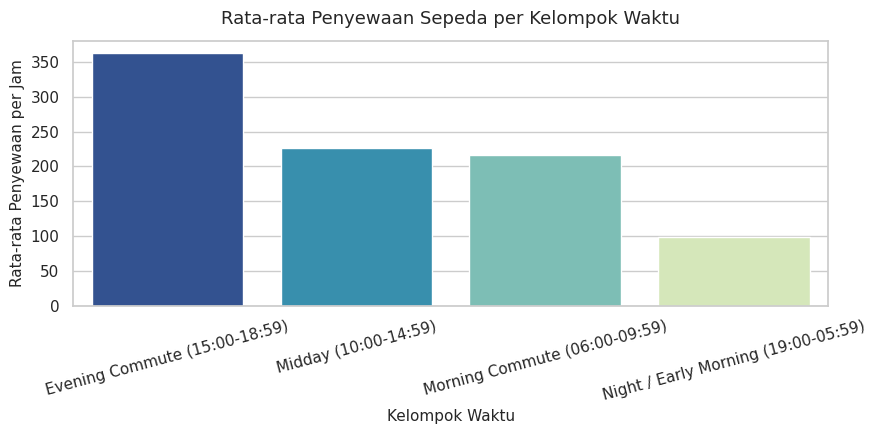

In [81]:
# Analisis Lanjutan: Manual Grouping / Binning Kelompok Waktu (Clustering Non-ML)
def categorize_time_of_day(hour):
    if 6 <= hour < 10:
        return 'Morning Commute (06:00-09:59)'
    elif 10 <= hour < 15:
        return 'Midday (10:00-14:59)'
    elif 15 <= hour < 19:
        return 'Evening Commute (15:00-18:59)'
    else:
        return 'Night / Early Morning (19:00-05:59)'

# Menerapkan fungsi binning ke hour_df
hour_df['time_group'] = hour_df['hr'].apply(categorize_time_of_day)

# Aggregasi rata-rata dan total penyewaan per kelompok waktu
time_group_analysis = hour_df.groupby('time_group')['cnt'].agg(
    mean_rentals='mean',
    total_rentals='sum',
    hours_count='count'
).reset_index().sort_values(by='mean_rentals', ascending=False)

print("=== Analisis Lanjutan: Binning Kelompok Waktu ===")
display(time_group_analysis)

# Visualisasi Analisis Lanjutan
plt.figure(figsize=(9, 4.5))
sns.barplot(
    data=time_group_analysis,
    x='time_group',
    y='mean_rentals',
    palette='YlGnBu_r'
)
plt.title('Rata-rata Penyewaan Sepeda per Kelompok Waktu', fontsize=13, pad=12)
plt.xlabel('Kelompok Waktu', fontsize=11)
plt.ylabel('Rata-rata Penyewaan per Jam', fontsize=11)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Insight:**
* **Clustering Non-ML (Binning Kelompok Waktu)**: Berhasil mengelompokkan jam operasional menjadi 4 kategori waktu utama.
* **Kelompok Waktu Paling Aktif**: Kelompok waktu **Evening Commute (15:00-18:59)** dan **Morning Commute (06:00-09:59)** mencatatkan rata-rata penyewaan per jam tertinggi dibandingkan rentang waktu *Midday* maupun *Night/Early Morning*.

## Conclusion & Recommendation

## Conclusion & Recommendation

* **Conclusion Pertanyaan 1**: Pada tahun 2012, rata-rata penyewaan sepeda harian tertinggi terjadi pada kondisi cuaca **Clear/Partly Cloudy** yaitu sebesar **6.004** unit per hari. Diikuti oleh kondisi cuaca **Misty/Cloudy** sebesar **4.991** unit per hari, dan mengalami penurunan paling drastis pada cuaca **Light Snow/Rain** yaitu hanya sebesar **2.126** unit per hari.
* **Conclusion Pertanyaan 2:** Selama tahun 2012, pada hari kerja (`workingday` = 1), pola penyewaan sepeda menunjukkan bahwa pengguna **Registered** sangat mendominasi pada jam komuter puncak (pukul 07.00–09.00 dan 17.00–19.00). Sementara pengguna **Casual** cenderung menggunakan sepeda secara bertahap pada siang hingga sore hari (pukul 11.00–16.00).


### Rekomendasi Action Item:
1. **Peningkatan Ketersediaan Armada Komuter**: Menyiapkan dan menyeimbangkan ketersediaan sepeda di stasiun-stasiun area perkantoran dan transit pada pukul 06.30 dan 16.30 di hari kerja guna mengantisipasi lonjakan pengguna Registered.
2. **Promosi Jam Off-Peak untuk Pengguna Casual**: Memberikan diskon atau insentif khusus bagi pengguna Casual di rentang waktu siang hari (pukul 10.00–15.00) untuk meningkatkan konversi menjadi pengguna Registered sekaligus mengoptimalkan penggunaan unit sepeda.